# 01 · Pseudobulk por donante y tipo celular

**Qué hacemos:** sumar los recuentos de `raw` de todas las células de un mismo tipo celular dentro de un mismo
donante. Pasamos de 24.000 células a unas 450 filas (donante, tipo), cada una con muchos más recuentos y, por
tanto, mucho menos ruido.

**Por qué:** la etiqueta ADNC es del donante. Si cada célula contara como muestra independiente tendríamos
"24.000 ejemplos" que en realidad son 75 donantes (*pseudorreplicación*). El pseudobulk es el equivalente a
promediar muchas medidas ruidosas del mismo canal antes de clasificar.

**Ejecución:** `jupyter nbconvert --to notebook --execute --inplace notebooks\01_pseudobulk.ipynb`

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tfm import pseudobulk as P
from tfm.config import load_config

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

cfg = load_config(ROOT)
COL, PB = cfg["columns"], cfg["pseudobulk"]
DON, CT, LAB = COL["donor"], COL["cell_type"], COL["label"]
ORDEN_TODAS, ORDEN = cfg["labels"]["all"], cfg["labels"]["classification"]
TABLAS, FIGS = cfg["paths"]["tables"], cfg["paths"]["figures"]
for d in (TABLAS, FIGS):
    d.mkdir(parents=True, exist_ok=True)
SALIDA = ROOT / PB["file"]
SALIDA.parent.mkdir(parents=True, exist_ok=True)
PALETA = dict(zip(ORDEN_TODAS, ["#9e9e9e", "#4daf4a", "#ff7f00", "#e41a1c"]))

def guardar(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", encoding="utf-8"); return df

def guardar_fig(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")

## 1. Construir el pseudobulk

Se lee `raw/X` (recuentos crudos, 36.412 genes) en bloques de células y se suman con una multiplicación por
una matriz indicadora: si `G[g, c] = 1` cuando la célula `c` pertenece al grupo `g`, entonces `G @ X` da la suma
por grupo. Así nunca se carga la matriz entera en memoria.

Se guardan **recuentos sumados** (enteros), no normalizados: la normalización se aplica después, al modelar.

In [2]:
pb = P.build_pseudobulk(cfg["paths"]["subset"], DON, CT, source=PB["source"], chunk_cells=PB["chunk_cells"],
                        donor_expected=cfg["donor_level_expected"])
pb.write_h5ad(SALIDA, compression="gzip")
print(pb)
print(f"\nGuardado en {SALIDA} ({SALIDA.stat().st_size / 1024**2:.0f} MB)")
print(f"Genes de raw que están entre los 6.000 HVG de X: {int(pb.var['en_X_hvg'].sum())}")

  células 4,000/24,000

  células 8,000/24,000

  células 12,000/24,000

  células 16,000/24,000

  células 20,000/24,000

  células 24,000/24,000


AnnData object with n_obs × n_vars = 472 × 36412
    obs: 'donor_id', 'cell_type_abbr', 'n_celulas', 'total_counts', 'n_genes_detectados', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'Neurotypical reference', 'Age at death', 'Years of education', 'Cognitive status', 'ADNC', 'Braak stage', 'Thal phase', 'CERAD score', 'APOE4 status', 'Lewy body disease pathology', 'LATE-NC stage', 'Microinfarct pathology', 'PMI', 'suspension_type', 'development_stage_ontology_term_id', 'Continuous Pseudo-progression Score', 'tissue_type', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage'
    var: 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'simbolo', 'en_X_hvg'
    uns: 'pseudobulk'

Guardado en C:\Users\ori\MEDAL\Code\Data\processed\pseudobulk.h5ad (23 MB)
Genes de raw que están entre los 6.000 HVG de X: 6000


## 2. Cuántos pseudobulk hay y cuántas células resume cada uno

Un pseudobulk de 5 células es mucho más ruidoso que uno de 200: es una media de pocas medidas. El umbral
mínimo (`min_cells` en el config) **no se aplica todavía**; aquí vemos a quién afectaría.

In [3]:
obs = pb.obs
tabla = obs.groupby([LAB, CT], observed=True)["n_celulas"].agg(["size", "median", "min", "max"]).unstack(CT)
resumen = pd.DataFrame({
    "pseudobulk": obs.groupby(LAB, observed=True).size(),
    "n_celulas_mediana": obs.groupby(LAB, observed=True)["n_celulas"].median(),
    f"con_<{PB['min_cells']}_celulas": obs[obs["n_celulas"] < PB["min_cells"]].groupby(LAB, observed=True).size(),
    "recuentos_mediana": obs.groupby(LAB, observed=True)["total_counts"].median().round(0),
}).reindex(ORDEN_TODAS).fillna(0)
resumen[f"con_<{PB['min_cells']}_celulas"] = resumen[f"con_<{PB['min_cells']}_celulas"].astype(int)
guardar(resumen, "pb_resumen_por_clase")
display(resumen)

esperados = obs[DON].nunique() * obs[CT].nunique()
print(f"Pares posibles {esperados}, existentes {len(obs)}: faltan {esperados - len(obs)} (donante sin células de ese tipo)")

,pseudobulk,n_celulas_mediana,con_<10_celulas,recuentos_mediana
ADNC,,,,
Reference,26,216.5,2,1699458.0
Low,72,74.0,1,929626.0
Intermediate,126,42.0,2,571726.0
High,248,21.0,40,223894.0


Pares posibles 480, existentes 472: faltan 8 (donante sin células de ese tipo)


## 3. ¿Lo técnico cambia con la clase?

Este es el riesgo que vimos en la ficha: como cada clase tiene 6.000 células repartidas entre más o menos
donantes, los pseudobulk de High suman menos células y menos recuentos. Si `n_celulas` o `total_counts`
cambian con la clase, un modelo puede "acertar" la clase por esa diferencia técnica.

`rho` es la correlación de Spearman entre la clase ordinal (Low=0, Intermediate=1, High=2) y la variable,
dentro de cada tipo celular, sin Reference.

,n_celulas_mediana_Low,n_celulas_mediana_Intermediate,n_celulas_mediana_High,n_celulas_rho,n_celulas_p,total_counts_mediana_Low,total_counts_mediana_Intermediate,total_counts_mediana_High,total_counts_rho,total_counts_p
cell_type_abbr,,,,,,,,,,
AST,55.5,44.0,20.0,-0.569,0.0,695480.0,571259.0,219605.0,-0.544,0.0
L2IT-GLU,74.0,46.0,24.0,-0.729,0.0,3191919.0,1582180.0,731200.0,-0.709,0.0
MGC,77.5,37.0,22.0,-0.617,0.0,531170.0,201781.0,139867.5,-0.496,0.0
OLG,69.5,29.0,18.0,-0.495,0.0,527963.5,243659.0,142973.0,-0.497,0.0
SST-GABA,60.0,44.0,22.0,-0.630,0.0,1010809.5,701226.0,301090.0,-0.545,0.0
VIP-GABA,92.5,43.0,22.5,-0.710,0.0,1742102.0,649300.0,330027.0,-0.656,0.0


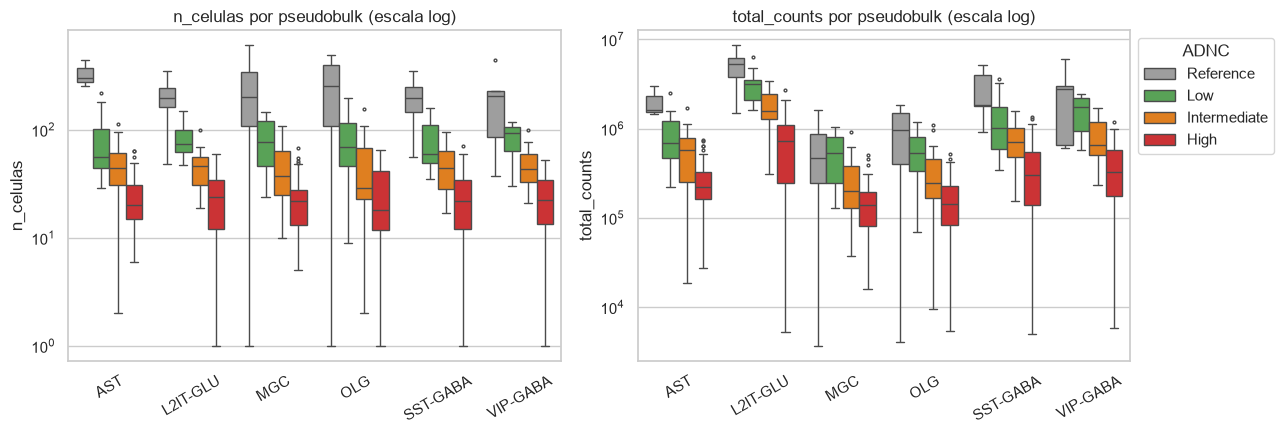

In [4]:
tec = guardar(P.technical_by_class(pb, cfg), "pb_tecnico_vs_clase")
display(tec[[c for c in tec.columns if c.endswith("_rho") or c.endswith("_p") or "mediana" in c]].round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, v in zip(axs, ["n_celulas", "total_counts"]):
    sns.boxplot(data=obs, x=CT, y=v, hue=LAB, hue_order=ORDEN_TODAS, palette=PALETA, ax=ax, fliersize=2)
    ax.set_yscale("log"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    ax.set_title(f"{v} por pseudobulk (escala log)")
axs[0].get_legend().remove(); axs[1].legend(title="ADNC", bbox_to_anchor=(1, 1))
fig.tight_layout(); guardar_fig(fig, "pb_tecnico_vs_clase"); plt.show()

## 4. Genes expresados por tipo celular

Muchos de los 36.412 genes apenas se detectan en un tipo celular dado. Un gen cuenta como **expresado** en un
tipo si tiene al menos `min_cpm` recuentos por millón en al menos `min_frac` de sus pseudobulk (la idea de
`filterByExpr` de edgeR). Este filtro **no usa la etiqueta**, así que no introduce fuga de información.

In [5]:
expr = P.expressed_genes(pb, CT, min_cpm=PB["min_cpm"], min_frac=PB["min_frac"])
genes_tipo = pd.DataFrame({
    "expresados": expr.sum(),
    "de_ellos_en_HVG_de_X": expr[pb.var["en_X_hvg"].to_numpy()].sum(),
})
guardar(genes_tipo, "pb_genes_expresados_por_tipo")
display(genes_tipo)
print(f"Expresados en al menos un tipo: {int(expr.any(axis=1).sum())} | en los 6: {int(expr.all(axis=1).sum())}")

,expresados,de_ellos_en_HVG_de_X
AST,15414,4305
L2IT-GLU,16632,3930
MGC,13370,3768
OLG,13230,3614
SST-GABA,15300,3801
VIP-GABA,16094,4120


Expresados en al menos un tipo: 19633 | en los 6: 11060


## 5. PCA: ¿qué domina la variación?

Normalizamos a **log-CPM** (cada pseudobulk escalado a un millón de recuentos y `log1p`) y hacemos una PCA.

- **Todos los tipos juntos:** debería separar los tipos celulares, que es con mucho la mayor fuente de variación.
- **Dentro de cada tipo, sin Reference:** aquí es donde tendría que verse la enfermedad. Medimos qué parte de la
  varianza de cada componente explican el ADNC, el número de células (técnico) y el donante.

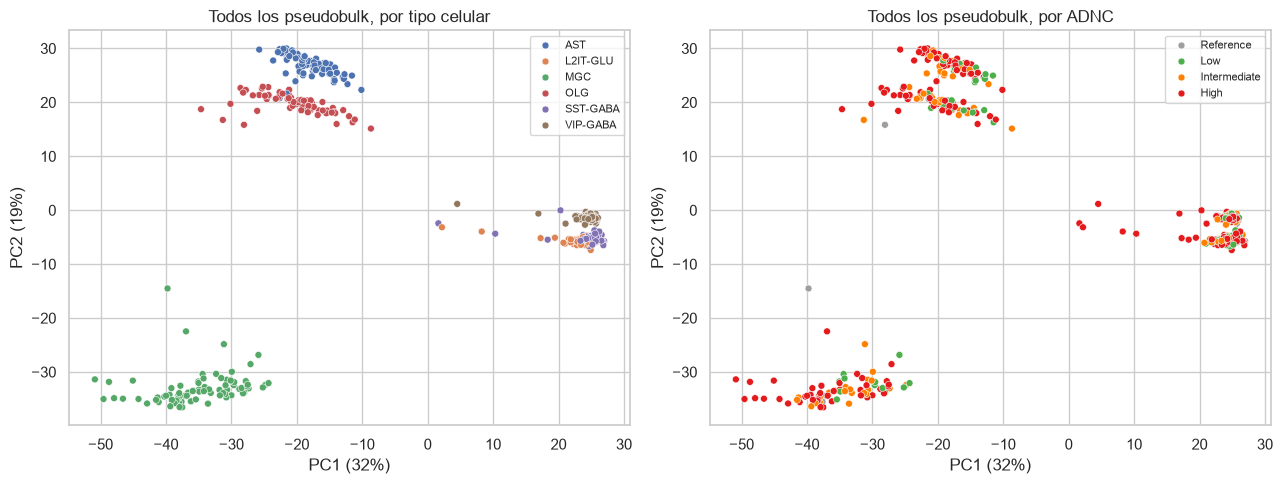

In [6]:
L = P.log_cpm(pb)
genes_ok = expr.any(axis=1).to_numpy()
pcs, var_exp, _ = P.pca(L[:, genes_ok], n_genes=PB["n_hvg_pca"], n_comps=10, seed=cfg["seed"])

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=obs[CT].values, ax=axs[0], s=25)
axs[0].set_title("Todos los pseudobulk, por tipo celular")
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=obs[LAB].values, hue_order=ORDEN_TODAS, palette=PALETA, ax=axs[1], s=25)
axs[1].set_title("Todos los pseudobulk, por ADNC")
for ax in axs:
    ax.set_xlabel(f"PC1 ({var_exp[0]:.0%})"); ax.set_ylabel(f"PC2 ({var_exp[1]:.0%})")
    ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
fig.tight_layout(); guardar_fig(fig, "pb_pca_global"); plt.show()

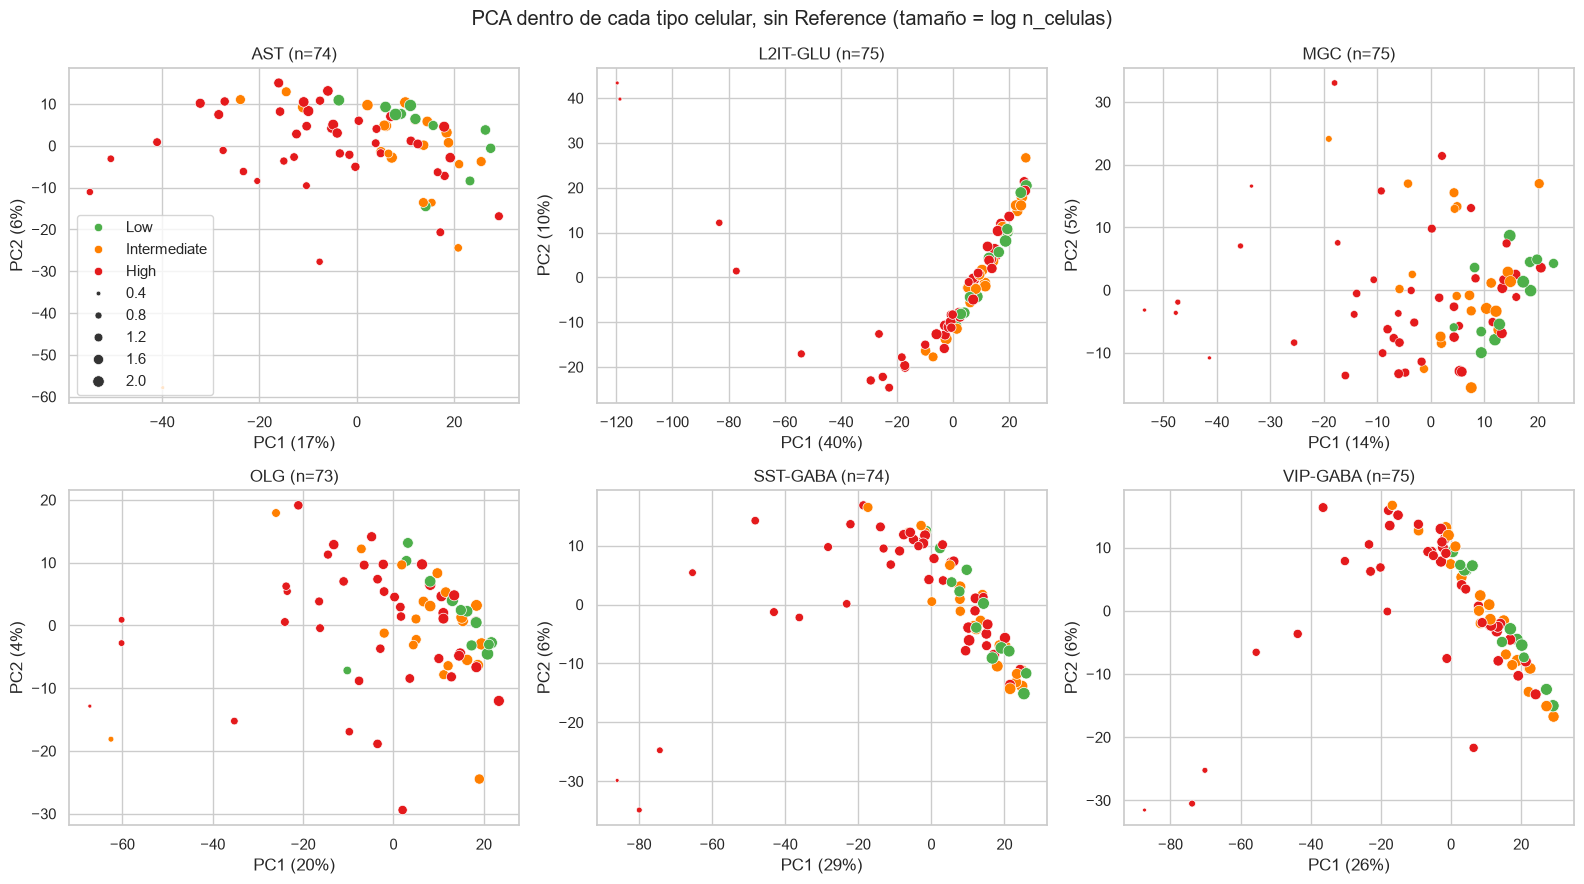

variable  ADNC                         log n_celulas                        
PC         PC1   PC2   PC3   PC4   PC5           PC1   PC2   PC3   PC4   PC5
tipo                                                                        
AST       0.19  0.03  0.01  0.00  0.07          0.18  0.44  0.09  0.00  0.01
L2IT-GLU  0.15  0.04  0.00  0.01  0.00          0.70  0.00  0.00  0.01  0.00
MGC       0.23  0.02  0.00  0.02  0.01          0.68  0.05  0.01  0.00  0.00
OLG       0.13  0.01  0.01  0.01  0.02          0.81  0.04  0.00  0.00  0.01
SST-GABA  0.19  0.02  0.00  0.01  0.00          0.76  0.00  0.00  0.00  0.01
VIP-GABA  0.20  0.00  0.00  0.01  0.00          0.67  0.07  0.00  0.00  0.01

In [7]:
tipos = sorted(obs[CT].unique())
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
filas_r2 = []
for ax, t in zip(axs.ravel(), tipos):
    m = ((obs[CT] == t) & obs[LAB].isin(ORDEN)).to_numpy()
    sub = obs[m]
    p, v, _ = P.pca(L[np.ix_(m, expr[t].to_numpy())], n_genes=PB["n_hvg_pca"], n_comps=5, seed=cfg["seed"])
    sns.scatterplot(x=p[:, 0], y=p[:, 1], hue=sub[LAB].values, hue_order=ORDEN, palette=PALETA,
                    size=np.log10(sub["n_celulas"].clip(lower=1)).values, sizes=(8, 80), ax=ax, legend=(t == tipos[0]))
    ax.set_title(f"{t} (n={m.sum()})"); ax.set_xlabel(f"PC1 ({v[0]:.0%})"); ax.set_ylabel(f"PC2 ({v[1]:.0%})")
    for nombre, valores in [("ADNC", sub[LAB].astype(str)), ("log n_celulas", np.log10(sub["n_celulas"].clip(lower=1)))]:
        for i, r2 in enumerate(P.r2_by(p, valores)):
            filas_r2.append({"tipo": t, "variable": nombre, "PC": f"PC{i+1}", "R2": r2, "var_explicada": v[i]})
fig.suptitle("PCA dentro de cada tipo celular, sin Reference (tamaño = log n_celulas)")
fig.tight_layout(); guardar_fig(fig, "pb_pca_por_tipo"); plt.show()

r2 = pd.DataFrame(filas_r2).pivot_table(index=["tipo", "PC"], columns="variable", values="R2")
guardar(r2, "pb_pca_r2_por_tipo")
display(r2.round(2).unstack("PC"))

## 6. Genes de Alzheimer y marcadores

Expresión media (log-CPM) por tipo celular. Los marcadores sirven de control: cada uno debería destacar en su
tipo (GFAP en astrocitos, P2RY12 en microglía...). Recuerda que APP, MAPT, TREM2 y GSK3B **no están** entre los
6.000 genes de `X`, pero sí aquí, porque el pseudobulk sale de `raw`.

No encontrados: []


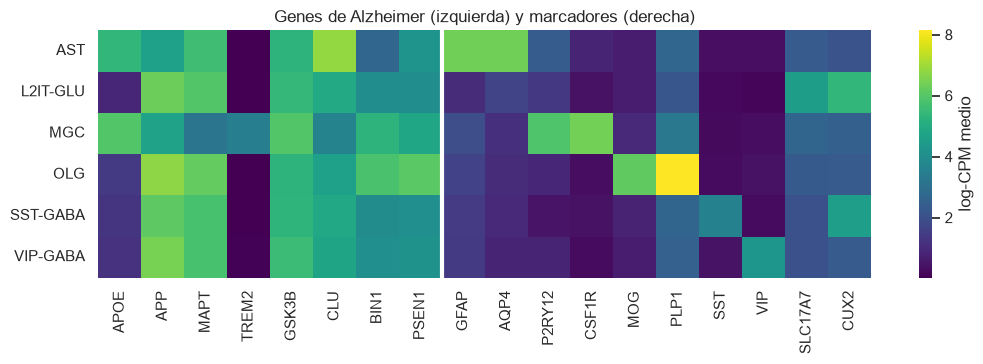

APOE   APP  MAPT  TREM2  GSK3B   CLU  BIN1  PSEN1
cell_type_abbr ADNC                                                           
AST            Low           5.46  4.69  5.66   0.03   5.27  6.80  2.83   4.29
               Intermediate  5.62  4.36  5.72   0.06   5.29  6.94  2.58   4.07
               High          5.12  4.69  5.62   0.03   5.26  6.78  2.67   4.28
L2IT-GLU       Low           1.09  6.30  5.92   0.00   5.47  4.92  3.91   4.17
               Intermediate  1.09  6.27  5.89   0.03   5.46  4.97  3.99   4.07
               High          0.76  6.32  5.96   0.07   5.38  4.92  3.98   3.90
MGC            Low           5.83  4.81  3.54   4.00   5.90  4.05  5.88   4.92
               Intermediate  6.05  4.69  3.44   3.57   5.86  3.93  5.38   4.98
               High          6.08  4.66  3.08   3.27   5.92  3.47  5.15   4.87
OLG            Low           1.62  6.80  6.27   0.00   5.18  4.64  5.84   6.18
               Intermediate  1.22  6.77  6.20   0.00   5.37  4.54  5.79   6.03
               High          1.35  6.73  6.18   0.05   5.19  4.71  5.81   6.03
SST-GABA       Low           1.30  6.16  5.81   0.08   5.45  4.92  3.88   4.23
               Intermediate  1.35  6.17  5.77   0.00   5.46  4.92  3.99   4.17
               High          1.24  6.06  5.78   0.02   5.18  4.87  3.90   3.89
VIP-GABA       Low           1.47  6.47  5.76   0.07   5.71  4.65  4.12   4.24
               Intermediate  0.99  6.44  5.75   0.09   5.68  4.78  4.12   4.22
               High          1.23  6.48  5.81   0.03   5.47  4.70  3.95   4.12

In [8]:
idx = P.gene_symbol_index(pb)
gi = cfg["genes_interes"]
genes = [g for g in gi["alzheimer"] + [m for v in gi["marcadores"].values() for m in v] if g in idx]
print("No encontrados:", [g for g in gi["alzheimer"] + [m for v in gi["marcadores"].values() for m in v] if g not in idx])

media = pd.DataFrame({g: pd.Series(L[:, idx[g]]).groupby(obs[CT].values).mean() for g in genes})
guardar(media, "pb_genes_interes_por_tipo")
fig, ax = plt.subplots(figsize=(1 + 0.55 * len(genes), 3.8))
sns.heatmap(media, cmap="viridis", ax=ax, cbar_kws={"label": "log-CPM medio"})
ax.axvline(len([g for g in gi["alzheimer"] if g in idx]), color="white", lw=3)
ax.set_title("Genes de Alzheimer (izquierda) y marcadores (derecha)")
fig.tight_layout(); guardar_fig(fig, "pb_genes_interes"); plt.show()

alz = [g for g in gi["alzheimer"] if g in idx]
sin_ref = obs[LAB].isin(ORDEN).to_numpy()
por_clase = pd.DataFrame({g: pd.Series(L[sin_ref, idx[g]]).groupby([obs[CT].values[sin_ref], obs[LAB].values[sin_ref]]).mean()
                          for g in alz})
por_clase.index.names = [CT, LAB]
por_clase = por_clase.reindex(pd.MultiIndex.from_product([tipos, ORDEN], names=[CT, LAB]))
guardar(por_clase, "pb_genes_alzheimer_por_tipo_y_clase")
display(por_clase.round(2))

In [9]:
resumen_json = {
    "pseudobulk": int(pb.n_obs), "genes": int(pb.n_vars), "fichero": str(SALIDA.relative_to(ROOT)),
    "pares_faltantes": int(esperados - len(obs)),
    "por_clase": resumen.reset_index().to_dict(orient="records"),
    "genes_expresados_por_tipo": genes_tipo["expresados"].to_dict(),
    "pca_global_var_PC1_PC2": [float(var_exp[0]), float(var_exp[1])],
    "rho_n_celulas_vs_clase": tec["n_celulas_rho"].round(3).to_dict(),
    "rho_total_counts_vs_clase": tec["total_counts_rho"].round(3).to_dict(),
}
(TABLAS / "pb_resumen.json").write_text(json.dumps(resumen_json, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(resumen_json, indent=2, ensure_ascii=False, default=str))

{
  "pseudobulk": 472,
  "genes": 36412,
  "fichero": "Data\\processed\\pseudobulk.h5ad",
  "pares_faltantes": 8,
  "por_clase": [
    {
      "ADNC": "Reference",
      "pseudobulk": 26,
      "n_celulas_mediana": 216.5,
      "con_<10_celulas": 2,
      "recuentos_mediana": 1699458.0
    },
    {
      "ADNC": "Low",
      "pseudobulk": 72,
      "n_celulas_mediana": 74.0,
      "con_<10_celulas": 1,
      "recuentos_mediana": 929626.0
    },
    {
      "ADNC": "Intermediate",
      "pseudobulk": 126,
      "n_celulas_mediana": 42.0,
      "con_<10_celulas": 2,
      "recuentos_mediana": 571726.0
    },
    {
      "ADNC": "High",
      "pseudobulk": 248,
      "n_celulas_mediana": 21.0,
      "con_<10_celulas": 40,
      "recuentos_mediana": 223894.0
    }
  ],
  "genes_expresados_por_tipo": {
    "AST": 15414,
    "L2IT-GLU": 16632,
    "MGC": 13370,
    "OLG": 13230,
    "SST-GABA": 15300,
    "VIP-GABA": 16094
  },
  "pca_global_var_PC1_PC2": [
    0.31699538230895996,
    0.188